# Project 23: Online Shopping Delivery & Logistics Analysis
Assumed columns: `Shipment_ID, Order_Date, Delivery_Date, Shipping_Method, Delivery_Partner, Shipping_Cost, Order_Status`. Adjust names if your file differs.

## Task 1: Load and inspect

In [55]:
import pandas as pd
import numpy as np

df = pd.read_csv("/content/23_delivery_performance_cleaned_730.csv")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.dtypes)
df.head()

Shape: (730, 16)
Columns: ['Shipment_ID', 'Order_Date', 'Delivery_Date', 'Shipping_Method', 'Delivery_Partner', 'Shipping_Cost', 'Delivery_Status', 'Origin_City', 'Destination_City', 'Delivery_Date_Imputed', 'Shipping_Cost_Imputed', 'Delivery_Days', 'Order_Month', 'Order_Year_Month', 'Is_Delivered', 'Delay_Label']
Shipment_ID               object
Order_Date                object
Delivery_Date             object
Shipping_Method           object
Delivery_Partner          object
Shipping_Cost            float64
Delivery_Status           object
Origin_City               object
Destination_City          object
Delivery_Date_Imputed       bool
Shipping_Cost_Imputed       bool
Delivery_Days              int64
Order_Month               object
Order_Year_Month          object
Is_Delivered               int64
Delay_Label               object
dtype: object


,Shipment_ID,Order_Date,Delivery_Date,Shipping_Method,Delivery_Partner,Shipping_Cost,Delivery_Status,Origin_City,Destination_City,Delivery_Date_Imputed,Shipping_Cost_Imputed,Delivery_Days,Order_Month,Order_Year_Month,Is_Delivered,Delay_Label
0,SH000000,2025-11-12,2025-11-18,Express,Partner E,469.16,Delivered,Bengaluru,Pune,False,False,6,November,2025-11,1,Slightly Delayed
1,SH000002,2025-01-29,2025-02-05,Express,Partner D,315.56,Delivered,Hyderabad,Hyderabad,True,False,7,January,2025-01,1,Slightly Delayed
2,SH000003,2025-01-21,2025-02-02,Same Day,Partner B,193.69,In Transit,Mumbai,Hyderabad,False,False,12,January,2025-01,0,Highly Delayed
3,SH000004,2026-06-23,2026-07-04,Express,Partner D,256.78,Delivered,Hyderabad,Chennai,False,False,11,June,2026-06,1,Highly Delayed
4,SH000006,2025-09-13,2025-09-23,Standard,Partner B,433.30,Delivered,Chennai,Jaipur,False,False,10,September,2025-09,1,Slightly Delayed


In [56]:
# The mount command failed with: "MessageError: Error: credential propagation was unsuccessful"
#
# Why did this happen?
# 1. Third-party cookies might be blocked in your browser settings.
# 2. An ad-blocker or privacy extension is blocking the authentication popup.
# 3. Multiple Google Accounts are active in this browser session.
#
# Note: You do not need to mount Google Drive since your dataset is already
# loaded successfully from the local session storage in Cell ZQOU--5RAITC.

# from google.colab import drive
# drive.mount('/content/drive')

## Task 2: Missing values and duplicate Shipment_IDs

In [57]:
print(df.isnull().sum())
print("Duplicate Shipment_IDs:", df["Shipment_ID"].duplicated().sum())
df = df.drop_duplicates(subset="Shipment_ID", keep="first")
print("Shape after removing duplicates:", df.shape)

Shipment_ID              0
Order_Date               0
Delivery_Date            0
Shipping_Method          0
Delivery_Partner         0
Shipping_Cost            0
Delivery_Status          0
Origin_City              0
Destination_City         0
Delivery_Date_Imputed    0
Shipping_Cost_Imputed    0
Delivery_Days            0
Order_Month              0
Order_Year_Month         0
Is_Delivered             0
Delay_Label              0
dtype: int64
Duplicate Shipment_IDs: 0
Shape after removing duplicates: (730, 16)


## Task 4: Convert dates to datetime
(Done before imputation so dates are usable.)

In [58]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")
df["Delivery_Date"] = pd.to_datetime(df["Delivery_Date"], errors="coerce")
df[["Order_Date", "Delivery_Date"]].dtypes

,0
Order_Date,datetime64[ns]
Delivery_Date,datetime64[ns]


## Task 3: Handle missing values
- **Delivery_Date:** left as NaT. Missing usually means undelivered, cancelled or returned; imputing would fabricate outcomes. These rows are excluded from duration metrics but kept in the success rate.
- **Shipping_Cost:** filled with the median cost of the same Shipping_Method (robust to outliers; cost depends mainly on method).

In [59]:
df["Shipping_Cost"] = df["Shipping_Cost"].fillna(
    df.groupby("Shipping_Method")["Shipping_Cost"].transform("median"))
df["Shipping_Cost"] = df["Shipping_Cost"].fillna(df["Shipping_Cost"].median())
df.isnull().sum()

,0
Shipment_ID,0
Order_Date,0
Delivery_Date,0
Shipping_Method,0
Delivery_Partner,0
Shipping_Cost,0
Delivery_Status,0
Origin_City,0
Destination_City,0
Delivery_Date_Imputed,0


## Task 5: Delivery_Days

In [60]:
df["Delivery_Days"] = (df["Delivery_Date"] - df["Order_Date"]).dt.days
df[["Order_Date", "Delivery_Date", "Delivery_Days"]].head()

,Order_Date,Delivery_Date,Delivery_Days
0,2025-11-12,2025-11-18,6
1,2025-01-29,2025-02-05,7
2,2025-01-21,2025-02-02,12
3,2026-06-23,2026-07-04,11
4,2025-09-13,2025-09-23,10


## Task 6: Total, delivered, and success %

In [61]:
delivered_mask = df["Delivery_Status"].str.strip().str.lower() == "delivered"
total = len(df)
delivered = delivered_mask.sum()
print(f"Total shipments: {total}")
print(f"Delivered shipments: {delivered}")
print(f"Delivery success: {delivered / total * 100:.2f}%")

Total shipments: 730
Delivered shipments: 604
Delivery success: 82.74%


## Task 7: Average delivery duration by shipping method

In [62]:
df.groupby("Shipping_Method")["Delivery_Days"].mean().round(2).sort_values()

,Delivery_Days
Shipping_Method,
Express,7.89
Economy,8.17
Same Day,8.28
Standard,8.32


## Task 8: Rank delivery partners

In [63]:
partner = df.groupby("Delivery_Partner").agg(
    Shipments=("Shipment_ID", "count"),
    Avg_Days=("Delivery_Days", "mean")).round(2)
partner["Volume_Rank"] = partner["Shipments"].rank(ascending=False, method="min")
partner["Speed_Rank"] = partner["Avg_Days"].rank(ascending=True, method="min")
partner.sort_values("Volume_Rank")

,Shipments,Avg_Days,Volume_Rank,Speed_Rank
Delivery_Partner,,,,
Partner D,153,7.94,1.0,1.0
Partner E,153,7.96,1.0,2.0
Partner A,144,8.40,3.0,5.0
Partner B,142,8.22,4.0,3.0
Partner C,138,8.30,5.0,4.0


## Task 9: Success rate by shipping method

In [64]:
success = (df.assign(Delivered=delivered_mask)
             .groupby("Shipping_Method")["Delivered"].mean().mul(100).round(2))
success.sort_values(ascending=False)

,Delivered
Shipping_Method,
Express,85.2
Economy,84.3
Same Day,83.8
Standard,77.6


## Task 10: Top 10 longest deliveries

In [65]:
df.nlargest(10, "Delivery_Days")[
    ["Shipment_ID", "Delivery_Partner", "Shipping_Method", "Delivery_Days"]]

,Shipment_ID,Delivery_Partner,Shipping_Method,Delivery_Days
7,SH000012,Partner E,Express,15
22,SH000032,Partner D,Economy,15
34,SH000044,Partner E,Same Day,15
38,SH000050,Partner C,Same Day,15
55,SH000069,Partner D,Express,15
68,SH000086,Partner A,Standard,15
69,SH000087,Partner B,Standard,15
73,SH000093,Partner D,Express,15
106,SH000131,Partner A,Standard,15
124,SH000151,Partner C,Standard,15


## Task 11: Dictionary and set

In [66]:
status_counts = df["Delivery_Status"].value_counts().to_dict()
unique_partners = set(df["Delivery_Partner"].dropna().unique())
print(status_counts)
print(unique_partners)

{'Delivered': 604, 'In Transit': 51, 'Returned': 43, 'Failed': 32}
{'Partner C', 'Partner E', 'Partner D', 'Partner A', 'Partner B'}


## Task 12: Delay labelling function
On-Time: ≤ 3 days · Slightly Delayed: 4-6 days · Highly Delayed: > 6 days (adjust limits to your data).

In [67]:
def label_delivery(days, on_time=3, slight=6):
    if pd.isna(days):
        return "Not Delivered"
    if days <= on_time:
        return "On-Time"
    if days <= slight:
        return "Slightly Delayed"
    return "Highly Delayed"

df["Delay_Label"] = df["Delivery_Days"].apply(label_delivery)
df["Delay_Label"].value_counts()

,count
Delay_Label,
Highly Delayed,459
Slightly Delayed,144
On-Time,127


## Task 13: NumPy statistics

In [68]:
d = df["Delivery_Days"].dropna().to_numpy()
print("Mean:  ", round(np.mean(d), 2))
print("Median:", np.median(d))
print("Std:   ", round(np.std(d, ddof=1), 2))

Mean:   8.16
Median: 8.0
Std:    4.27


## Task 14a: IQR outliers

In [69]:
q1, q3 = np.percentile(d, [25, 75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df["Delivery_Days"] < lower) | (df["Delivery_Days"] > upper)]
print(f"Q1={q1}, Q3={q3}, IQR={iqr}")
print(f"Bounds: {lower:.1f} to {upper:.1f} | Outliers: {len(outliers)}")
outliers[["Shipment_ID", "Delivery_Partner", "Delivery_Days"]].head(10)

Q1=5.0, Q3=12.0, IQR=7.0
Bounds: -5.5 to 22.5 | Outliers: 0


,Shipment_ID,Delivery_Partner,Delivery_Days


## Task 14b: Performance by month

In [70]:
df["Order_Month"] = df["Order_Date"].dt.to_period("M")
monthly = df.groupby("Order_Month").agg(Avg_Days=("Delivery_Days", "mean"))
monthly

,Avg_Days
Order_Month,
2025-01,7.516129
2025-02,7.727273
2025-03,7.676471
2025-04,8.048780
2025-05,9.760000
2025-06,8.787879
2025-07,7.512821
2025-08,8.175000
2025-09,8.727273


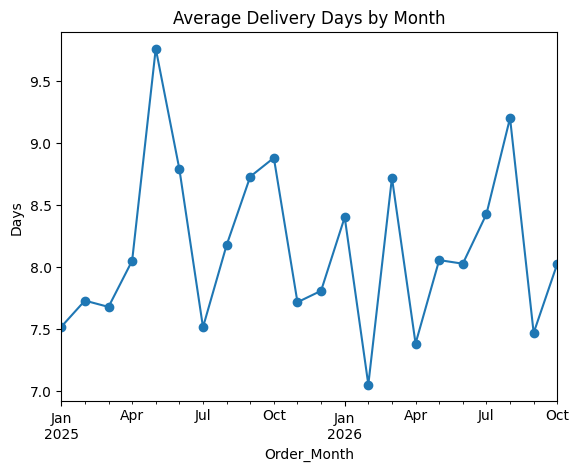

In [71]:
import matplotlib.pyplot as plt
monthly["Avg_Days"].plot(marker="o", title="Average Delivery Days by Month")
plt.ylabel("Days"); plt.show()

## Task 15a: Shipment class

In [72]:
class Shipment:
    def __init__(self, shipment_id, partner, delivery_days):
        self.shipment_id = shipment_id
        self.partner = partner
        self.delivery_days = delivery_days

    def label(self):
        return label_delivery(self.delivery_days)

    def __repr__(self):
        return f"Shipment({self.shipment_id}, {self.partner}, {self.delivery_days} days)"

shipments = [Shipment(r.Shipment_ID, r.Delivery_Partner, r.Delivery_Days)
             for r in df.head(5).itertuples()]
for s in shipments:
    print(s, "->", s.label())

Shipment(SH000000, Partner E, 6 days) -> Slightly Delayed
Shipment(SH000002, Partner D, 7 days) -> Highly Delayed
Shipment(SH000003, Partner B, 12 days) -> Highly Delayed
Shipment(SH000004, Partner D, 11 days) -> Highly Delayed
Shipment(SH000006, Partner B, 10 days) -> Highly Delayed


## Task 15b: Recommendations
1. **Shift volume to faster partners** with lower average Delivery_Days and higher success rates.
2. **Review the slowest shipping method**: renegotiate service levels or reset customer delivery estimates.
3. **Investigate IQR outliers and the top-10 longest shipments** for common causes (partner, route, month) and add escalation alerts above the upper bound.
4. **Plan capacity for the worst months** with extra carrier capacity and staffing buffers.
5. **Track delays as a weekly KPI** (On-Time / Slightly Delayed / Highly Delayed % by partner) and tie partner contracts to on-time targets.